<a href="https://colab.research.google.com/github/Japi20/Data201-labs/blob/main/assignments/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 8
### Data 201
### Jorge Pineda

## Part 1- Experiment with α

In [12]:
%pip -q install ISLP

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score



In [14]:
hitters = load_data("Hitters")
hitters = hitters.dropna(subset=["Salary"]).copy()

X = hitters.drop(columns="Salary")
y = hitters["Salary"]

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Categorical predictors:", category_cols)

Training rows: 197
Test rows: 66
Categorical predictors: ['League', 'Division', 'NewLeague']


In [15]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
        ])

In [16]:
alpha_values = [0.1, 10, 100]
rows = []
lasso_models = {}

for a in alpha_values:
    pipe = Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', Lasso(alpha=a, max_iter=30000))
    ])

    pipe.fit(X_train, y_train)

    #save each fitted pipeline for later coefficient inspection.
    lasso_models[a] = pipe

    #get the model's coefficients.
    coefs = pipe.named_steps['model'].coef_

    #add one dictionary of results for this alpha.
    rows.append({
        'alpha': a,
        'Training RMSE': np.sqrt(
            mean_squared_error(y_train, pipe.predict(X_train))
        ),
        'Test RMSE': np.sqrt(
            mean_squared_error(y_test, pipe.predict(X_test))
        ),
        'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6))
    })

alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,alpha,Training RMSE,Test RMSE,Nonzero coefficients
0,0.1,289.38,356.83,19
1,10.0,303.10,381.84,9
2,100.0,341.39,395.12,5


**Questions**:
1. As α increases, what happens to the number of retained predictors?

As alpha increases, stronger Lasso
regularization sets more coefficients to zero, so fewer predictors are retained in this experiment.

---

2. Does a smaller number of predictors always lead to a lower test RMSE?

No, fewer predictors do not always lead to a lower test RMSE. In these results, reducing the retained predictors from 19 to 5 increased test RMSE from 356.83 to 395.12. Removing predictors can help, but it can also remove useful information.



---



## Part 2 - Visualize and interpret

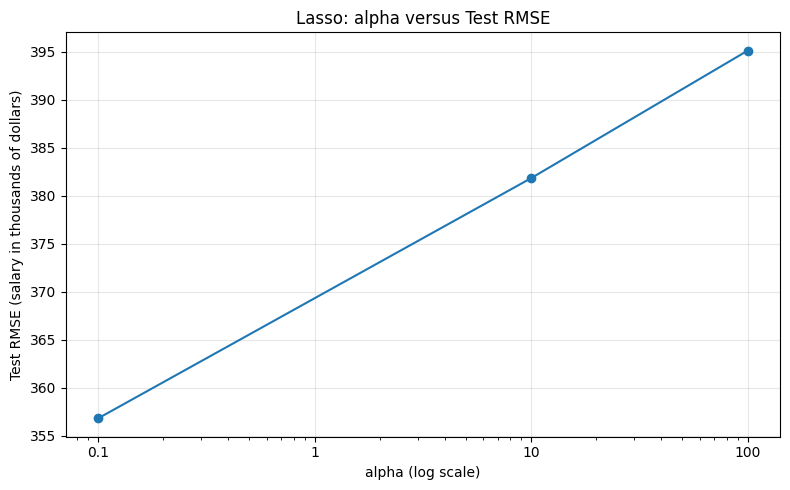

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.semilogx(
    alpha_table['alpha'],
    alpha_table['Test RMSE'],
    marker='o'
)

ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('Test RMSE (salary in thousands of dollars)')
ax.set_title('Lasso: alpha versus Test RMSE')
ax.set_xticks([0.1, 1, 10, 100])
ax.set_xticklabels(['0.1', '1', '10', '100'])
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Questions:**
1. Which α produces the lowest test RMSE among the three values?

Alpha = 0.1 produces the lowest test RMSE among the three values, at 356.83.


---


2. Which α appears to cause the most underfitting? Explain using bias.

Alpha = 100 appears to cause the most underfitting. It has the strongest penalty and the highest training and test RMSE. The stronger restriction adds bias by limiting how well the model can capture useful relationships between the predictors and salary.

---

3. Why might a model with higher training RMSE produce lower test RMSE?

A model with higher training RMSE may fit the training sample less closely while getting patterns that work better for new observations. Regularization can reduce overfitting this way and lead to lower test RMSE (yet his did not happen with the three alpha values we tested, both training and test RMSE increased as alpha increased).

---

## Part 3- Model interpretation

In [18]:
lasso_100 = lasso_models[100]

feature_names = lasso_100.named_steps['preprocess'].get_feature_names_out()
coefs = lasso_100.named_steps['model'].coef_

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefs
})

coef_table['Lasso is zero'] = np.isclose(
    coef_table['Coefficient'], 0, atol=1e-6
)

display(coef_table.round(2))

,Feature,Coefficient,Lasso is zero
0,num__AtBat,0.00,True
1,num__Hits,76.59,False
2,num__HmRun,0.00,True
3,num__Runs,0.00,True
4,num__RBI,0.00,True
5,num__Walks,16.17,False
6,num__Years,0.00,True
7,num__CAtBat,0.00,True
8,num__CHits,0.00,True
9,num__CHmRun,0.00,True


1. Identify two predictors that Lasso sets to zero at α = 100.

At alpha = 100, Lasso sets the coefficients for AtBat and HmRun to zero.

---
2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary? Explain.

No, a zero coefficient only means this Lasso model does not use that predictor at alpha = 100. The predictor could still be related to salary, but another predictor may provide similar information, or the penalty may be strong enough to remove useful information.

---
3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance.

I would prefer the model with fewer predictors because it is easier to interpret while giving very similar predictive performance. It would let us explain the predictions using fewer variables without losing much accuracy.

## Part 4 - Choosing the Right Regression Model

#### **Scenario A**

I would choose lasso because there are more predictors than patients, which creates a high risk of overfitting. Lasso can set some coefficients to zero, reducing model complexity and helping identify a smaller group of measurements that is easier to interpret. Cross-validation would help choose the penalty strength.

#### **Scenario B**

I would choose ridge because it can reduce overfitting by shrinking coefficients while keeping all predictors. This fits the goal of retaining useful information from strongly correlated predictors, even though keeping 40 predictors makes the model less simple to interpret.

#### **Scenario C**

I would choose ordinary linear regression because there are many observations and only three predictors, so model complexity is already low. With an approximately linear relationship, it provides a simple model that is easy to interpret, and overfitting is less of a concern than in a setting with many predictors and little data.

#### **Scenario D**

I would choose not sure because the number of observations and predictors alone does not tell us which model will predict best. I would compare ordinary linear regression, Ridge, and Lasso using cross-validation on the training data, including tuning alpha for Ridge and Lasso. Since prediction is the priority, I would use validation performance to guide the choice rather than selecting the simplest model automatically.